In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
print("Ready!")

Ready!


In [2]:
n = 5000

materials = {"Steel": 200e9, "Aluminium": 70e9, "Timber": 10e9}   # E in Pa
supports  = ["simply_supported", "cantilever"]

df = pd.DataFrame({
    "length_m":  np.random.uniform(1, 5, n),
    "load_kN":   np.random.uniform(1, 50, n),
    "width_m":   np.random.uniform(0.05, 0.3, n),
    "height_m":  np.random.uniform(0.1, 0.5, n),
    "material":  np.random.choice(list(materials), n),
    "support":   np.random.choice(supports, n),
})
df["E_GPa"] = df["material"].map(materials) / 1e9

# --- Beam theory ---
P = df["load_kN"] * 1e3
L = df["length_m"]
E = df["E_GPa"] * 1e9
I = df["width_m"] * df["height_m"]**3 / 12
c = df["height_m"] / 2

is_cant = df["support"] == "cantilever"
M     = np.where(is_cant, P * L,              P * L / 4)
delta = np.where(is_cant, P * L**3 / (3*E*I), P * L**3 / (48*E*I))

df["max_stress_MPa"]     = M * c / I / 1e6
df["max_deflection_mm"]  = delta * 1e3

# 2% noise to mimic real measurements
df["max_stress_MPa"]    *= np.random.normal(1, 0.02, n)
df["max_deflection_mm"] *= np.random.normal(1, 0.02, n)

df.to_csv("data/beam_data.csv", index=False)
df.head()

,length_m,load_kN,width_m,height_m,material,support,E_GPa,max_stress_MPa,max_deflection_mm
0,2.498160,20.288140,0.143410,0.299868,Aluminium,cantilever,70.0,23.942598,4.526086
1,4.802857,24.198347,0.133228,0.398699,Aluminium,simply_supported,70.0,8.199631,1.171628
2,3.927976,42.872822,0.094038,0.325067,Steel,cantilever,200.0,101.380006,16.468098
3,3.394634,17.660215,0.201817,0.133321,Steel,simply_supported,200.0,25.652509,1.791074
4,1.624075,43.612835,0.169156,0.174232,Timber,simply_supported,10.0,20.546266,5.317353


In [3]:
print(df.shape)
df.describe()

(5000, 9)


,length_m,load_kN,width_m,height_m,E_GPa,max_stress_MPa,max_deflection_mm
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2.987328,25.082869,0.175344,0.303074,96.604000,39.928821,65.282473
std,1.158535,13.995209,0.072692,0.115122,80.440794,89.260939,540.772910
min,1.000047,1.002589,0.050039,0.100101,10.000000,0.063577,0.000303
25%,1.975451,13.110150,0.111792,0.205092,10.000000,4.550076,0.289608
50%,3.000035,24.812607,0.174049,0.304980,70.000000,13.269698,2.127017
75%,3.992403,36.935208,0.240155,0.400442,200.000000,37.216392,15.186526
max,4.998871,49.975754,0.299951,0.499970,200.000000,2010.380235,29865.529645


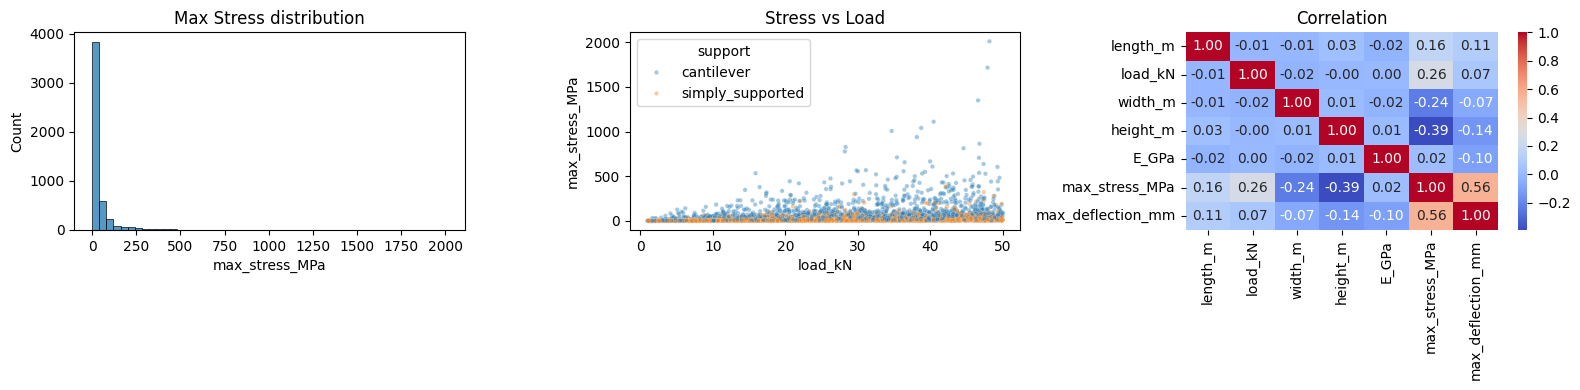

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["max_stress_MPa"], bins=50, ax=axes[0])
axes[0].set_title("Max Stress distribution")

sns.scatterplot(data=df, x="load_kN", y="max_stress_MPa",
                hue="support", alpha=0.4, s=10, ax=axes[1])
axes[1].set_title("Stress vs Load")

sns.heatmap(df.select_dtypes("number").corr(), annot=True,
            fmt=".2f", cmap="coolwarm", ax=axes[2])
axes[2].set_title("Correlation")

plt.tight_layout()
plt.savefig("data/eda.png", dpi=150)
plt.show()

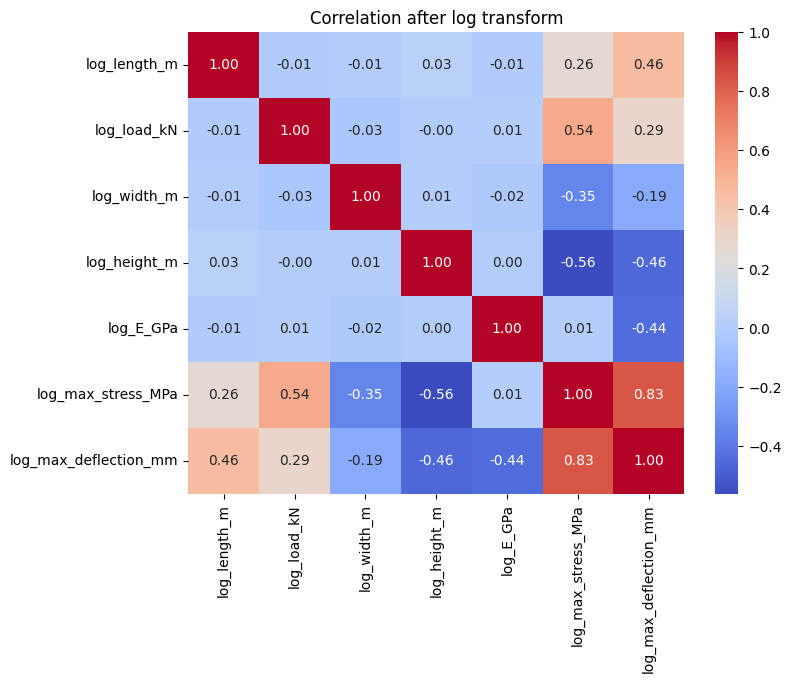

In [5]:
for col in ["length_m", "load_kN", "width_m", "height_m", "E_GPa",
            "max_stress_MPa", "max_deflection_mm"]:
    df["log_" + col] = np.log(df[col])

log_cols = [c for c in df.columns if c.startswith("log_")]
plt.figure(figsize=(8, 6))
sns.heatmap(df[log_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation after log transform")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_percentage_error

df["is_cantilever"] = (df["support"] == "cantilever").astype(int)

raw_X = ["length_m", "load_kN", "width_m", "height_m", "E_GPa", "is_cantilever"]
log_X = ["log_length_m", "log_load_kN", "log_width_m", "log_height_m",
         "log_E_GPa", "is_cantilever"]
y = df["max_stress_MPa"]

train, test = train_test_split(df, test_size=0.2, random_state=42)

results = {}

# 1. Linear on raw
lr_raw = LinearRegression().fit(train[raw_X], train["max_stress_MPa"])
results["Linear (raw)"] = lr_raw.predict(test[raw_X])

# 2. Linear on log  -> convert back with exp
lr_log = LinearRegression().fit(train[log_X], train["log_max_stress_MPa"])
results["Linear (log)"] = np.exp(lr_log.predict(test[log_X]))

# 3. Random Forest on raw
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(train[raw_X], train["max_stress_MPa"])
results["Random Forest"] = rf.predict(test[raw_X])

for name, pred in results.items():
    print(f"{name:15s}  R² = {r2_score(test['max_stress_MPa'], pred):.4f}   "
          f"MAPE = {mean_absolute_percentage_error(test['max_stress_MPa'], pred)*100:.2f}%")

Linear (raw)     R² = 0.4607   MAPE = 1385.28%
Linear (log)     R² = 0.9995   MAPE = 1.58%
Random Forest    R² = 0.9431   MAPE = 19.83%


In [7]:
pd.Series(lr_log.coef_, index=log_X).round(3)

log_length_m     1.000
log_load_kN      1.000
log_width_m     -1.000
log_height_m    -1.999
log_E_GPa       -0.000
is_cantilever    1.387
dtype: float64

In [8]:
X_tr, X_te = train[log_X], test[log_X]

lr_def = LinearRegression().fit(X_tr, train["log_max_deflection_mm"])
pred_lin = np.exp(lr_def.predict(X_te))

rf_def = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_def.fit(train[raw_X], train["max_deflection_mm"])
pred_rf = rf_def.predict(test[raw_X])

for name, pred in [("Linear (log)", pred_lin), ("Random Forest", pred_rf)]:
    print(f"{name:15s}  R² = {r2_score(test['max_deflection_mm'], pred):.4f}   "
          f"MAPE = {mean_absolute_percentage_error(test['max_deflection_mm'], pred)*100:.2f}%")

pd.Series(lr_def.coef_, index=log_X).round(3)

Linear (log)     R² = 0.9997   MAPE = 1.61%
Random Forest    R² = -2.2450   MAPE = 613.26%


log_length_m     3.000
log_load_kN      1.001
log_width_m     -1.000
log_height_m    -2.999
log_E_GPa       -1.000
is_cantilever    2.774
dtype: float64

In [9]:
rf_log = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_log.fit(train[log_X], train["log_max_deflection_mm"])
pred_rf_log = np.exp(rf_log.predict(test[log_X]))

print(f"RF (log)  R² = {r2_score(test['max_deflection_mm'], pred_rf_log):.4f}   "
      f"MAPE = {mean_absolute_percentage_error(test['max_deflection_mm'], pred_rf_log)*100:.2f}%")

RF (log)  R² = 0.7293   MAPE = 32.90%


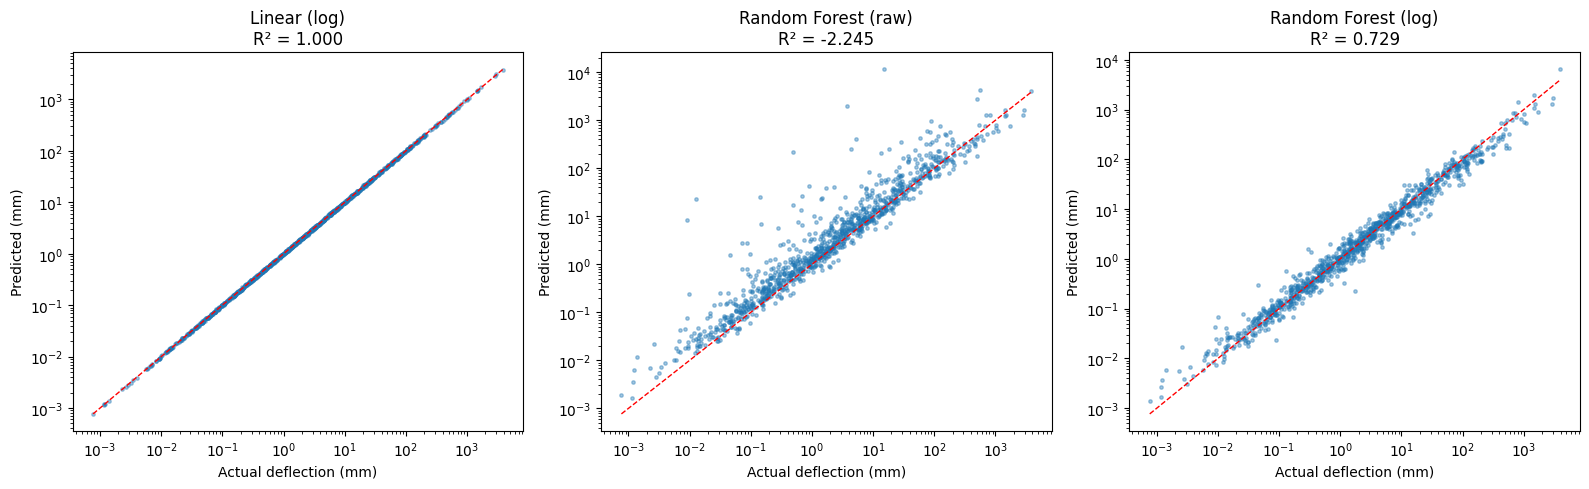

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
actual = test["max_deflection_mm"]

for ax, (name, pred) in zip(axes, [("Linear (log)", pred_lin),
                                   ("Random Forest (raw)", pred_rf),
                                   ("Random Forest (log)", pred_rf_log)]):
    ax.scatter(actual, pred, s=6, alpha=0.4)
    lims = [actual.min(), actual.max()]
    ax.plot(lims, lims, "r--", lw=1)          # perfect prediction line
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{name}\nR² = {r2_score(actual, pred):.3f}")
    ax.set_xlabel("Actual deflection (mm)"); ax.set_ylabel("Predicted (mm)")

plt.tight_layout()
plt.savefig("data/pred_vs_actual.png", dpi=150)
plt.show()

In [11]:
import joblib
joblib.dump(lr_log, "data/stress_model.pkl")
joblib.dump(lr_def, "data/deflection_model.pkl")
print("Models saved!")

Models saved!
